In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

# Q2.

In [2]:
def UpdateLoss(X, y, w):
    
    # prediction
    y_pred = np.exp(-X @ w)
    residual = y_pred - y
    
    # total loss for all data points: sum of squared loss
    loss = np.sum(residual**2)
    
    # gradient of loss function: sum of gradients for all data points, reshaped to be a column vector
    gradient = np.sum(-2 * (y_pred - y) * y_pred * X, axis=0).reshape(-1,1)

    # Or you can try:
    # gradient = X.T @ (-2 * (y_pred - y) * y_pred)

    return loss, gradient

In [3]:
def GradDesc(X, y, lr, maxIterations):
    Loss = []
    
    # Initialize w to be [[0], [0]]
    w = np.zeros((2,1))
    
    # Calculate first loss and gradient according to current X and y
    loss, gradient = UpdateLoss(X, y, w)
    Loss.append(loss)
    print('Iter 1: loss =', loss)
    
    for iteration in range(2, maxIterations+1):
        Loss.append(loss)
        
        # Gradient descend
        w = w - lr*gradient
        
        # update loss and gradient after each updation of w
        loss, gradient = UpdateLoss(X, y, w)
        
        if(iteration % 200000 == 0) or iteration==2:            
            print('Iter', iteration, ': loss =', loss)
    return Loss, w

In [4]:
df_expenditure = pd.read_csv('/Users/yutongdu/Documents/Teachings_TA/EE2211/Code/Data/government-expenditure-on-education.csv')

X = df_expenditure['year'].to_numpy().reshape(-1,1)
y = df_expenditure['recurrent_expenditure_total'].to_numpy().reshape(-1,1)

**Normalize features (year), since the model is exponential**\
e.g. e^1981 will yield a large gradient, where this large gradient will cause randomly large step in gradient descend

**Use polynomialFeatures( ) to add a ones column, in order to introduce a bias term in my model**

In [5]:
X_norm = X/X.max()   # normalization
poly = PolynomialFeatures(1)
X_train = poly.fit_transform(X_norm)

y_train = y/y.max()

Conclusively, the shape of vectors are:
- `X_train`: [n, 2]
- `y`: [n, 1]
- `w`: [2, 1]

In gradient descent, `gradient`($g$) should have the same shape as `w`, as $w(n+1) = w(n) - \eta \times g $.

Consequently, in `UpdateLoss`, we define:
- `y_pred`: [n, 1]
- `y_pred * (y_pred - y)`: [n, 1]
- `y_pred * (y_pred - y) * X`: [n, 2]
- `np.sum(y_pred * (y_pred - y) * X, axis=0)`: [1, 2], sum up all samples' gradients (sum along row axis)
- `np.sum(y_pred * (y_pred - y) * X, axis=0).reshape(-1,1)`: [2, 1], reshape to column vector

In [6]:
maxIterations = int(2e6)
lr = 0.03
Loss, w = GradDesc(X_train, y_train, lr, maxIterations)

Iter 1: loss = 16.729110005154975
Iter 2 : loss = 8.546351412713127
Iter 200000 : loss = 0.31849640829206255
Iter 400000 : loss = 0.11571614185341529
Iter 600000 : loss = 0.09255219266484509
Iter 800000 : loss = 0.08902107178127885
Iter 1000000 : loss = 0.08842366924894618
Iter 1200000 : loss = 0.08831833190389524
Iter 1400000 : loss = 0.08829943780903227
Iter 1600000 : loss = 0.08829602434209836
Iter 1800000 : loss = 0.08829540577000924
Iter 2000000 : loss = 0.08829529352983506


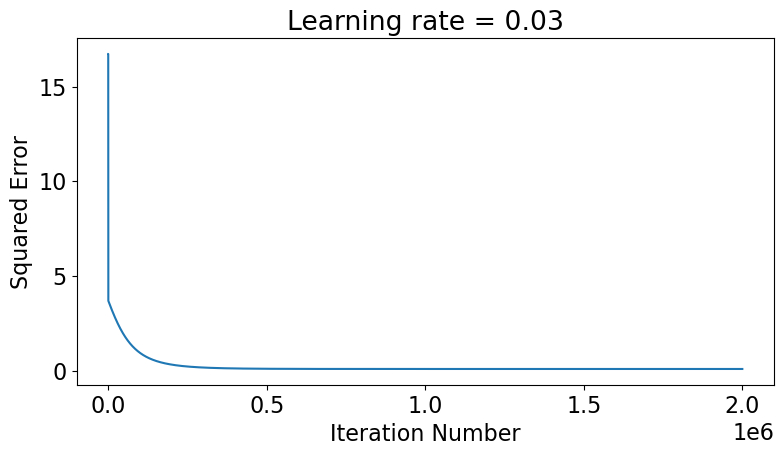

In [7]:
plt.figure(0, figsize=[9,4.5])
plt.rcParams.update({'font.size': 16})
plt.plot(np.arange(0, maxIterations, 1), Loss)
plt.xlabel('Iteration Number') 
plt.ylabel('Squared Error')
plt.xticks(np.arange(0, maxIterations+1, 500000))
plt.title('Learning rate = ' + str(lr))
plt.show()

**Normalize the test data accordingly**

In [8]:
test = np.arange(X.min(), 2024, 1).reshape(-1,1)
test_norm = test/X.max()    # normalize test data (same nomalizer)
X_test = poly.transform(test_norm)
pred_y = np.exp(- X_test@ w)

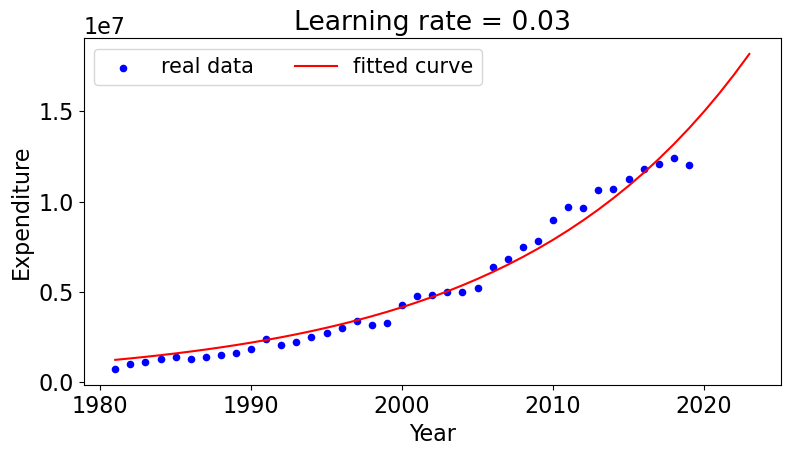

In [9]:
# Plot extrapolation
plt.figure(1, figsize=[9,4.5])
plt.rcParams.update({'font.size': 16})
plt.scatter(X, y, s=20, marker='o', c='blue', label='real data')
plt.plot(test, pred_y*y.max(), c='red', label='fitted curve')
plt.xlabel('Year') 
plt.ylabel('Expenditure')
plt.title('Learning rate = ' + str(lr))
plt.legend(loc='upper left',ncol=3, fontsize=15)
plt.show()

**Use big learning rate to train the model again**

In [10]:
lr_big = 0.1
Loss_big_lr, w_big_lr = GradDesc(X_train, y_train, lr_big, maxIterations)

Iter 1: loss = 16.729110005154975
Iter 2 : loss = 10.605108054784484
Iter 200000 : loss = 8.919997937313246
Iter 400000 : loss = 5.047836610495793
Iter 600000 : loss = 10.216047026623233
Iter 800000 : loss = 4.900020341844775
Iter 1000000 : loss = 9.284950324396624
Iter 1200000 : loss = 10.274267742329005
Iter 1400000 : loss = 9.314307501116867
Iter 1600000 : loss = 8.394639393278647
Iter 1800000 : loss = 4.060282295534446
Iter 2000000 : loss = 0.09887393517195638


**Use small learning rate to train the model again**

In [11]:
lr_small = 0.001
Loss_small_lr, w_small_lr = GradDesc(X_train, y_train, lr_small, maxIterations)

Iter 1: loss = 16.729110005154975
Iter 2 : loss = 13.165628754149337
Iter 200000 : loss = 3.4087508979750765
Iter 400000 : loss = 3.127023949804767
Iter 600000 : loss = 2.860036191141399
Iter 800000 : loss = 2.6096618239633376
Iter 1000000 : loss = 2.377042627105439
Iter 1200000 : loss = 2.1626480349284987
Iter 1400000 : loss = 1.9663788195874257
Iter 1600000 : loss = 1.7876908916587446
Iter 1800000 : loss = 1.6257199517574008
Iter 2000000 : loss = 1.4793940323450865


**Compare the value of loss function**

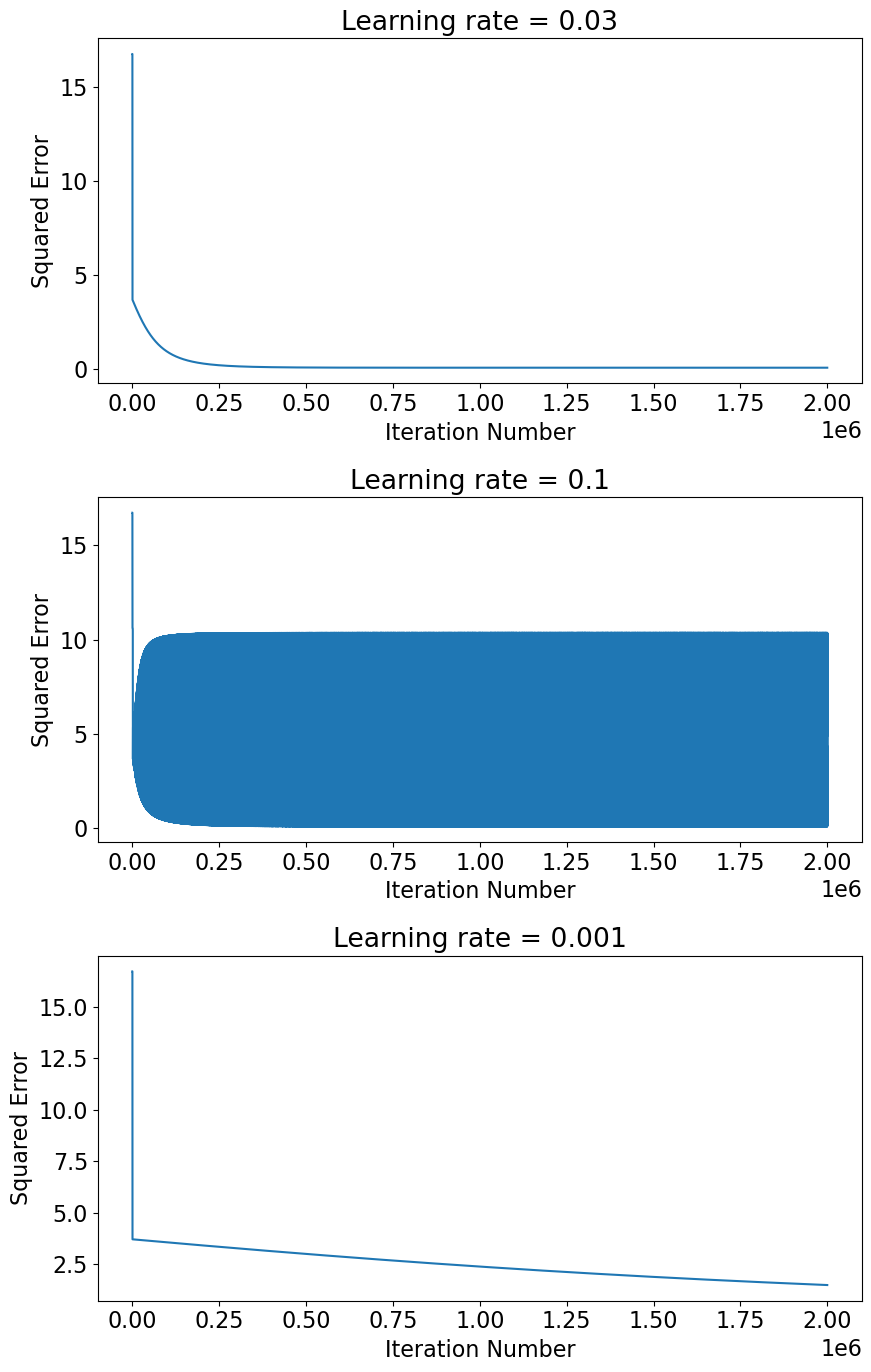

In [12]:
plt.rcParams.update({'font.size': 16})

fig, axs = plt.subplots(3,1, figsize=[9,14])
axs[0].plot(np.arange(0, maxIterations, 1), Loss)
axs[0].set_xlabel('Iteration Number') 
axs[0].set_ylabel('Squared Error')
axs[0].set_title('Learning rate = ' + str(lr))

axs[1].plot(np.arange(0, maxIterations, 1), Loss_big_lr)
axs[1].set_xlabel('Iteration Number') 
axs[1].set_ylabel('Squared Error')
axs[1].set_title('Learning rate = ' + str(lr_big))


axs[2].plot(np.arange(0, maxIterations, 1), Loss_small_lr)
axs[2].set_xlabel('Iteration Number') 
axs[2].set_ylabel('Squared Error')
axs[2].set_title('Learning rate = ' + str(lr_small))

plt.tight_layout()
plt.show()